# E2 x vector on the matched 2000 clip pilot

Use the original pilot's exact 2,000 files and speaker split. A frozen pretrained
VoxCeleb speaker encoder supplies 512-dimensional, length-normalized embeddings.
Only the standard scaler and LR accent head learn from this project's labels.
This is transfer learning, not training the speaker network from scratch.
Use the **Singlish final fusion (Python 3.14)** kernel. The existing local checkpoint
is pinned and hashed; no package installation runs in this notebook.

In [1]:
from pathlib import Path
import sys, json, hashlib, inspect
import joblib
import librosa
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from IPython.display import display

working = Path.cwd().resolve()
PROJECT_ROOT = next(p for p in [working, *working.parents]
                    if (p / 'notebooks/experiment_common.py').exists() and (p / 'data').is_dir())
sys.path.insert(0, str(PROJECT_ROOT / 'notebooks'))
import experiment_common as common
config = common.configure(PROJECT_ROOT, PROJECT_ROOT / 'data/e1_audio_1000x2/data')
RANDOM_SEED = common.SEED
SAMPLE_RATE = common.SAMPLE_RATE
MAX_SECONDS = common.MAX_SECONDS
MODEL_KEY = 'e2_xvector'
OUTPUT_DIR = config['output'] / MODEL_KEY
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(json.dumps(common.environment(), indent=2))

{
  "python": "3.14.7",
  "packages": {
    "numpy": "2.5.3",
    "scipy": "1.18.1",
    "scikit-learn": "1.9.1",
    "librosa": "1.0.0",
    "torch": "2.14.0",
    "transformers": "4.57.6",
    "nbclient": "0.11.0"
  }
}


## 1 Reuse the exact pilot manifest and speaker partitions

In [2]:
frame, fingerprint = common.prepare_manifest(config)
assert len(frame) == 2000 and frame.groupby('label').size().to_dict() == {0: 1000, 1: 1000}
split = common.shared_split(config, frame, fingerprint)
train_idx, val_idx, test_idx = [split[name] for name in ['train', 'validation', 'test']]
trainval_idx = np.sort(np.r_[train_idx, val_idx])
labels = frame.label.to_numpy()
groups = frame.group.to_numpy(dtype=str)
assert [len(train_idx), len(val_idx), len(test_idx)] == [1280, 320, 400]
# Hashes, clip IDs, speaker IDs, labels, and row order are identical to the earlier pilot.
preparation_sha256 = hashlib.sha256(inspect.getsource(common.prepare_audio).encode()).hexdigest()
print('Shared preparation SHA256:', preparation_sha256)

Clips: {0: 1000, 1: 1000}
Speakers: {0: 300, 1: 583}
Dataset SHA256: 872f8ffa700bb810105b9796d6c0032c6d8c07bd9b3ffedfb6239a179d6fa8cb
{
  "train": {
    "clips": 1280,
    "speakers": 566,
    "label_counts": {
      "0": 640,
      "1": 640
    }
  },
  "validation": {
    "clips": 320,
    "speakers": 141,
    "label_counts": {
      "0": 160,
      "1": 160
    }
  },
  "test": {
    "clips": 400,
    "speakers": 176,
    "label_counts": {
      "0": 200,
      "1": 200
    }
  }
}
Speaker overlap: 0. This is one fixed grouped split, not five-fold evaluation.
Shared preparation SHA256: cee82f490ec24817ffdce8d1393b1e83fc550f85727cd6fa11c1908402f97fc1


## 2 Extract frozen embeddings using the shared audio preparation

The common loader applies mono 16 kHz, a 30 dB silence trim, peak normalization
before the six-second cap, and padding to one second when necessary. This is the
existing pilot preparation, not the final 40k dataset's RMS-normalized preparation.
All clips pass through the frozen encoder in evaluation mode and their embeddings
are length-normalized. Cache identity includes the clip/audio fingerprint, preparation
code, checkpoint revision, and checkpoint hashes. Any failed clip stops the run.

In [3]:
import torch
from speechbrain.inference.speaker import EncoderClassifier
MODEL_NAME = 'speechbrain/spkrec-xvect-voxceleb'
MODEL_REVISION = '56895a2df401be4150a159f3a1c653f00051d477'
DEVICE = 'cuda:0' if torch.cuda.is_available() else 'cpu'
torch.manual_seed(RANDOM_SEED)
torch.set_num_threads(4)
source_dir = PROJECT_ROOT / 'outputs/xvector/pretrained_xvector'
# Pin to the exact previously downloaded checkpoint. No accent fine-tuning.
snapshot = (source_dir / 'hyperparams.yaml').readlink().parent
assert snapshot.name == MODEL_REVISION, 'Checkpoint revision changed'
checkpoint_hashes = {p.name: hashlib.sha256(p.read_bytes()).hexdigest()
                     for p in sorted(snapshot.iterdir()) if p.is_file()}
settings = {'fingerprint': fingerprint, 'preparation_sha256': preparation_sha256,
            'model': MODEL_NAME, 'revision': MODEL_REVISION,
            'checkpoint_sha256': checkpoint_hashes, 'length_normalized': True,
            'extraction': 'encode_batch per clip, inference_mode, eval, frozen'}
cache_key = hashlib.sha256(json.dumps(settings, sort_keys=True).encode()).hexdigest()
CACHE_PATH = OUTPUT_DIR / 'embeddings.npz'
X = None
if CACHE_PATH.exists():
    with np.load(CACHE_PATH, allow_pickle=False) as cached:
        if str(cached['key']) == cache_key:
            assert np.array_equal(cached['clip_ids'], frame.clip_id.to_numpy(dtype=str))
            X = cached['X'].copy()
            print('Reuse verified full 2000-clip embedding cache')
if X is None:
    encoder = EncoderClassifier.from_hparams(
        source=str(snapshot), savedir=str(OUTPUT_DIR / 'pretrained'),
        overrides={'pretrained_path': str(snapshot)}, run_opts={'device': DEVICE})
    encoder.mods.eval()
    for parameter in encoder.mods.parameters():
        parameter.requires_grad_(False)
    vectors = []
    for number, path in enumerate(frame.path, 1):
        waveform, real_samples = common.prepare_audio(Path(path))
        signal = torch.from_numpy(waveform).unsqueeze(0).to(DEVICE)
        with torch.inference_mode():
            vector = encoder.encode_batch(signal).detach().cpu().numpy().reshape(-1).astype(np.float32)
        if vector.shape != (512,) or not np.isfinite(vector).all():
            raise ValueError(f'Invalid embedding for {path}; preserve the matched clip list')
        norm = np.linalg.norm(vector)
        if norm <= 1e-12:
            raise ValueError(f'Zero embedding for {path}')
        vectors.append(vector / norm)
        if number % 100 == 0:
            print(f'{MODEL_KEY} {DEVICE}: {number}/{len(frame)}', flush=True)
    X = np.vstack(vectors)
    np.savez_compressed(CACHE_PATH, key=np.array(cache_key), X=X,
                        clip_ids=frame.clip_id.to_numpy(dtype=str))
    del encoder
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
assert X.shape == (2000, 512) and np.isfinite(X).all()
representation = {'type': 'x vector', 'dimension': 512,
    'model': MODEL_NAME, 'revision': MODEL_REVISION, 'checkpoint_sha256': checkpoint_hashes,
    'pretraining': 'VoxCeleb speaker recognition', 'frozen': True, 'length_normalized': True,
    'embedding_cache_key': cache_key}
print('Features:', X.shape, '| device:', DEVICE)

/home/mh/miniconda3/envs/singlish-py314/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


e2_xvector cuda:0: 100/2000


e2_xvector cuda:0: 200/2000


e2_xvector cuda:0: 300/2000


e2_xvector cuda:0: 400/2000


...

e2_xvector cuda:0: 1700/2000


e2_xvector cuda:0: 1800/2000


e2_xvector cuda:0: 1900/2000


e2_xvector cuda:0: 2000/2000


Features: (2000, 512) | device: cuda:0


## 3 Inspect the representation using training fitted PCA

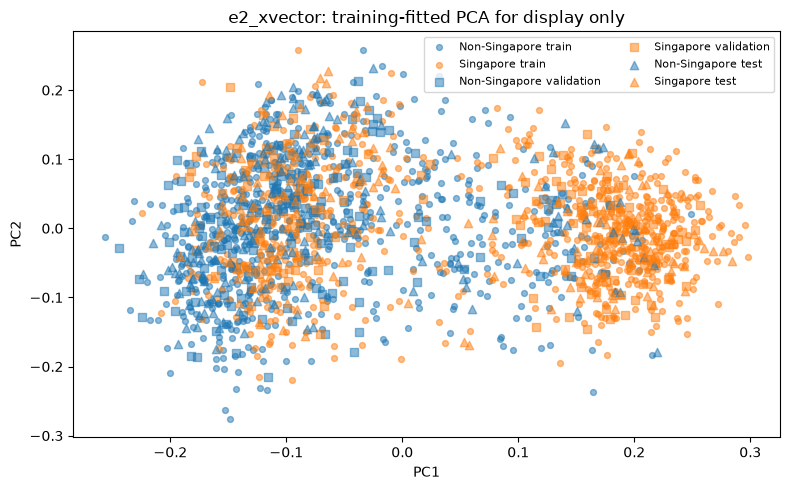

In [4]:
from sklearn.decomposition import PCA
projection = PCA(n_components=2, random_state=RANDOM_SEED).fit(X[train_idx])
points = projection.transform(X)
fig, ax = plt.subplots(figsize=(8, 5))
for part, marker in [('train', 'o'), ('validation', 's'), ('test', '^')]:
    for label, color in [(0, 'tab:blue'), (1, 'tab:orange')]:
        idx = split[part][labels[split[part]] == label]
        ax.scatter(points[idx, 0], points[idx, 1], c=color, marker=marker, alpha=.5,
                   s=18 if part == 'train' else 36, label=f'{common.CLASS_NAMES[label]} {part}')
ax.set(title=MODEL_KEY + ': training-fitted PCA for display only', xlabel='PC1', ylabel='PC2')
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'embedding_pca.png', dpi=150)
plt.show()
plt.close(fig)

## 4 Select the accent head on validation

Use the same LR candidate grid and selection rule as the pilot's acoustic and
Whisper LR heads. Each candidate scaler fits training clips only. The 320 validation
clips select C; the test clips never enter selection.

In [5]:
candidates = [
    (f'C={c:g}', Pipeline([
        ('scale', StandardScaler()),
        ('classifier', LogisticRegression(C=c, class_weight='balanced', max_iter=5000,
                                          random_state=RANDOM_SEED)),
    ])) for c in [0.01, 0.1, 1.0, 10.0, 100.0]
]
selected_model, validation = common.choose_candidate(candidates, X, labels, split)
common.write_json(OUTPUT_DIR / 'validation_selection.json', validation)

candidate  macro_f1  balanced_accuracy
   C=0.01  0.978125           0.978125
    C=0.1  0.981249           0.981250
      C=1  0.978123           0.978125
     C=10  0.984375           0.984375
    C=100  0.987500           0.987500
Validation choice: C=100


## 5 Refit the head on development and test once

Keep the encoder frozen. Refit the chosen scaler and classifier on the 1,600 training
plus validation clips, then score the same 400 test clips as the original pilot.
Save aligned predictions, per-class metrics, a confusion matrix, and whole-speaker
bootstrap intervals for paired comparison.

{
  "accuracy": 0.965,
  "macro_f1": 0.9649991249781245,
  "balanced_accuracy": 0.965,
  "roc_auc": 0.9947250000000001,
  "errors": 14,
  "confusion_matrix": [
    [
      192,
      8
    ],
    [
      6,
      194
    ]
  ],
  "confusion_matrix_labels": [
    0,
    1
  ],
  "brier_score": 0.026408977806568146,
  "speaker_bootstrap_ci95": {
    "accuracy": [
      0.9448621553884712,
      0.9824120603015075
    ],
    "balanced_accuracy": [
      0.9447603435320134,
      0.9822887786758576
    ],
    "macro_f1": [
      0.9448618090452261,
      0.9823722650421429
    ]
  }
}


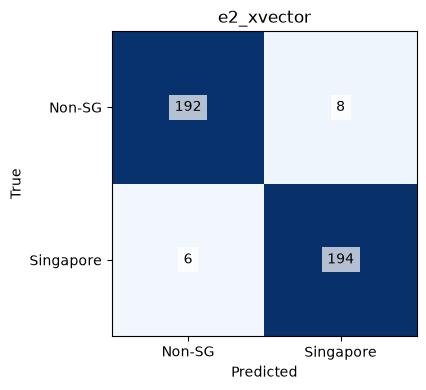

,clip_id,path,group,label,prediction,score_class_1,error
0,non_singapore/speaker_024/clip_001.wav,/home/mh/nusproj/singlish-whisper/data/e1_audi...,non_singapore::speaker_024,0,1,1.000000,True
1,non_singapore/speaker_073/clip_001.wav,/home/mh/nusproj/singlish-whisper/data/e1_audi...,non_singapore::speaker_073,0,1,0.748968,True
2,non_singapore/speaker_104/clip_003.wav,/home/mh/nusproj/singlish-whisper/data/e1_audi...,non_singapore::speaker_104,0,1,0.643255,True
3,non_singapore/speaker_164/clip_001.wav,/home/mh/nusproj/singlish-whisper/data/e1_audi...,non_singapore::speaker_164,0,1,0.999912,True
4,non_singapore/speaker_205/clip_003.wav,/home/mh/nusproj/singlish-whisper/data/e1_audi...,non_singapore::speaker_205,0,1,0.999820,True
5,non_singapore/speaker_225/clip_004.wav,/home/mh/nusproj/singlish-whisper/data/e1_audi...,non_singapore::speaker_225,0,1,0.867917,True
6,non_singapore/speaker_225/clip_005.wav,/home/mh/nusproj/singlish-whisper/data/e1_audi...,non_singapore::speaker_225,0,1,0.992695,True
7,non_singapore/speaker_268/clip_004.wav,/home/mh/nusproj/singlish-whisper/data/e1_audi...,non_singapore::speaker_268,0,1,0.999982,True
8,singapore/speaker_066/clip_001.wav,/home/mh/nusproj/singlish-whisper/data/e1_audi...,singapore::speaker_066,1,0,0.118804,True
9,singapore/speaker_184/clip_004.wav,/home/mh/nusproj/singlish-whisper/data/e1_audi...,singapore::speaker_184,1,0,0.254470,True


In [6]:
# Keep the representation fixed; refit the selected scaler and LR head on development.
classifier = clone(selected_model).fit(X[trainval_idx], labels[trainval_idx])
predictions = classifier.predict(X[test_idx])
probabilities = classifier.predict_proba(X[test_idx])[:, 1]
report = common.save_result(config, MODEL_KEY, frame, fingerprint, split, classifier,
    predictions, probabilities, validation, probability=True,
    extra={'representation': representation, 'features': int(X.shape[1]),
           'preparation_sha256': preparation_sha256,
           'training': 'Representation fixed before validation; selected scaler and LR refit on train plus validation',
           'comparison': 'Retrospective extension of the existing 2000-clip pilot; test has been inspected before'})
np.savez_compressed(OUTPUT_DIR / 'features_and_split.npz', X=X,
    clip_ids=frame.clip_id.to_numpy(dtype=str), paths=frame.path.to_numpy(dtype=str),
    labels=labels, groups=groups, fingerprint=np.array(fingerprint), **split)
display(pd.read_csv(OUTPUT_DIR / 'test_errors.csv'))

## Interpretation and limits

These results now use the same 2,000 files, audio preparation, speaker partitions,
and 400 held-out clips as the original matched pilot. The saved per-clip predictions
support paired comparisons. The earlier 200-clip demonstration is backed up separately;
its 40-test-clip score is not this result.

The shared LR search selects validation macro F1, then balanced accuracy, then the
first candidate (smaller C) on an exact tie, matching the original pilot's LR heads.
Only the selected scaler and accent head are refitted on the 1,600 development clips.
The test does not select settings. This extends an already inspected test retrospectively;
it is not a new untouched test or full cross-validation. Speaker bootstrap intervals
condition on this fitted model and split and exclude training and selection uncertainty.

Class and source remain linked: Singapore is MNSC and non-Singapore is Common Voice.
Speaker separation does not remove microphone, prompt, or corpus differences.
Different representations are intentional experimental differences, so results compare
complete pipelines rather than isolate architecture alone. Logistic regression's
probabilities are not explicitly calibrated. Do not claim an independent generalization
gain from a close pilot ranking.

## Recorded matched pilot result

Test BA: **96.50%**; macro F1: **0.9650**; errors: **14/400**. Validation selected **C=100**. All 2,000 clip identities and the shared 1,280/320/400 speaker split verified.

Results: `../outputs/matched_2000_seed42/e2_xvector/`. Combined pilot: `../outputs/matched_2000_seed42/embedding_extension_report.md`.